In [1]:
# Teste de Conhecimento 1 – Inteligência Artificial
# Unifap 2026.2

## Regressão para estimar o valor de empréstimo de um cliente

# Uma fintech quer automatizar parte da análise de crédito. Com a base histórica base_credito.csv,
# este notebook treina um modelo de regressão que estima o valor de empréstimo que pode ser
# oferecido a um novo cliente a partir das características dele.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def reais(valor):
    # formata um número no padrão brasileiro: R$ 1.234,56
    return f"R$ {valor:,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")

In [3]:
## Etapa 1 – Carregar os dados

dados = pd.read_csv("base_credito.csv")

print(f"A base tem {dados.shape[0]} linhas e {dados.shape[1]} colunas.")
dados

A base tem 50000 linhas e 5 colunas.


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54
...,...,...,...,...,...
49995,38,8818.70,760,94.72,47301.48
49996,55,11501.96,728,75.57,50408.79
49997,46,7374.09,479,91.25,22142.20
49998,29,2290.91,739,95.07,24040.33


In [4]:
## Etapa 2 – Conhecer os dados

dados.info()

### Variáveis de entrada (características do cliente):
# idade, renda_mensal, score_credito e historico_pagamentos.

### Variável que deve ser prevista (saída):
# valor_emprestimo.

### Tipos de dados presentes na base:
# Todas as colunas são numéricas. idade e score_credito são números inteiros (int64);
# renda_mensal, historico_pagamentos e valor_emprestimo são números decimais (float64).
# Não há colunas de texto nem categorias, então a base pode ser usada direto no modelo.

### Significado de cada variável:
# idade                -> idade do cliente, em anos (de 18 a 70 na base)
# renda_mensal         -> quanto o cliente ganha por mês, em reais
# score_credito        -> pontuação de crédito, de 300 a 850 (quanto maior, menor o risco de calote)
# historico_pagamentos -> nota de 0 a 100 sobre como o cliente pagou suas contas no passado
# valor_emprestimo     -> valor do empréstimo que foi aprovado para o cliente, em reais

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   idade                 50000 non-null  int64  
 1   renda_mensal          50000 non-null  float64
 2   score_credito         50000 non-null  int64  
 3   historico_pagamentos  50000 non-null  float64
 4   valor_emprestimo      50000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 1.9 MB


In [5]:
## Etapa 3 – Analisar os dados

print("Valores ausentes por coluna:")
print(dados.isnull().sum())
print(f"\nLinhas duplicadas: {dados.duplicated().sum()}")

print("\nCorrelação de cada variável com o valor do empréstimo:")
print(dados.corr()["valor_emprestimo"].drop("valor_emprestimo").round(3))

dados.describe().round(2)

Valores ausentes por coluna:
idade                   0
renda_mensal            0
score_credito           0
historico_pagamentos    0
valor_emprestimo        0
dtype: int64

Linhas duplicadas: 0

Correlação de cada variável com o valor do empréstimo:
idade                   0.041
renda_mensal            0.887
score_credito           0.358
historico_pagamentos    0.077
Name: valor_emprestimo, dtype: float64


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
count,50000.00,50000.00,50000.00,50000.00,50000.00
mean,40.08,7542.18,649.58,81.84,31736.16
std,10.78,4524.26,84.65,11.21,14456.33
min,18.00,1500.00,300.00,16.21,1000.00
25%,33.00,4463.35,592.00,75.16,22018.21
50%,40.00,6452.30,650.00,83.72,29039.42
75%,47.00,9395.70,707.00,90.33,38275.93
max,70.00,50000.00,850.00,100.00,150000.00


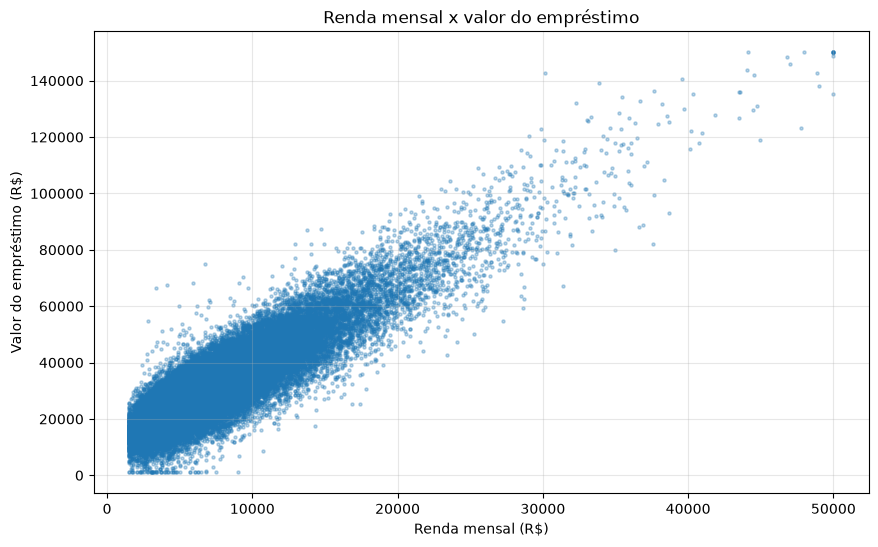

In [6]:
plt.figure(figsize=(10, 6))

plt.scatter(dados["renda_mensal"], dados["valor_emprestimo"], s=5, alpha=0.3)

plt.title("Renda mensal x valor do empréstimo")
plt.xlabel("Renda mensal (R$)")
plt.ylabel("Valor do empréstimo (R$)")
plt.grid(True, alpha=0.3)

plt.show()

In [7]:
### O que os dados mostram

# A base não tem valores ausentes nem linhas repetidas, então não foi preciso fazer limpeza.
# A renda mensal é a variável mais ligada ao valor do empréstimo (correlação de 0,887). No gráfico,
# quanto maior a renda, maior o empréstimo aprovado, e os pontos formam uma faixa que sobe quase em linha reta.
# Essa faixa vai ficando mais larga conforme a renda cresce: clientes com a mesma renda podem receber
# valores bem diferentes, sinal de que as outras variáveis também pesam na decisão.
# O score de crédito vem em seguida (0,358). Idade (0,041) e histórico de pagamentos (0,077) quase não
# se relacionam sozinhos com o valor, mas podem ajudar quando combinados com as demais no modelo.
# Também existem valores extremos: rendas de até R$ 50.000 e empréstimos que vão de R$ 1.000 a R$ 150.000,
# enquanto metade dos clientes ganha entre R$ 4.463 e R$ 9.396 por mês.

In [8]:
## Etapa 4 – Preparar os dados

entradas = ["idade", "renda_mensal", "score_credito", "historico_pagamentos"]

X = dados[entradas]
y = dados["valor_emprestimo"]

# 70% dos registros para treinar o modelo e 30% para testá-lo com clientes que ele nunca viu.
# O random_state fixo faz a divisão ser sempre a mesma quando o notebook é executado de novo.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=10)

print(f"Total de registros: {len(dados)}")
print(f"Treinamento: {len(X_treino)} registros ({len(X_treino) / len(dados):.0%})")
print(f"Teste: {len(X_teste)} registros ({len(X_teste) / len(dados):.0%})")

Total de registros: 50000
Treinamento: 35000 registros (70%)
Teste: 15000 registros (30%)


In [9]:
## Etapa 5 – Treinar o modelo

# Algoritmo escolhido: Regressão Linear Múltipla (usa as quatro características ao mesmo tempo)

modelo = LinearRegression()            # cria o modelo

modelo.fit(X_treino, y_treino)         # treina com os 70% de treinamento

previsoes = modelo.predict(X_teste)    # gera as previsões para os 30% de teste

print("Coeficientes aprendidos pelo modelo:")
for variavel, coeficiente in zip(entradas, modelo.coef_):
    print(f"  {variavel}: {coeficiente:.2f}")
print(f"  intercepto: {modelo.intercept_:.2f}")

# Leitura dos coeficientes: mantendo as outras variáveis iguais, cada R$ 1 a mais de renda aumenta o
# empréstimo previsto em cerca de R$ 2,83; cada ponto a mais de score soma cerca de R$ 60,78; cada ponto
# de histórico de pagamentos soma cerca de R$ 97,50; e cada ano de idade soma cerca de R$ 56,24.

Coeficientes aprendidos pelo modelo:
  idade: 56.24
  renda_mensal: 2.83
  score_credito: 60.78
  historico_pagamentos: 97.50
  intercepto: -39331.12


In [10]:
## Etapa 6 – Avaliar o modelo

mae = mean_absolute_error(y_teste, previsoes)
rmse = mean_squared_error(y_teste, previsoes) ** 0.5
r2 = r2_score(y_teste, previsoes)

print(f"MAE (erro absoluto médio): {reais(mae)}")
print(f"RMSE (raiz do erro quadrático médio): {reais(rmse)}")
print(f"R² (coeficiente de determinação): {r2:.4f}")
print(f"\nValor médio dos empréstimos no conjunto de teste: {reais(y_teste.mean())}")

MAE (erro absoluto médio): R$ 3.039,13
RMSE (raiz do erro quadrático médio): R$ 4.081,07
R² (coeficiente de determinação): 0.9216

Valor médio dos empréstimos no conjunto de teste: R$ 31.870,91


In [11]:
### O que as métricas significam

# MAE de R$ 3.039,13: em média, a previsão erra o valor do empréstimo em cerca de R$ 3 mil, para mais ou
# para menos. Como o empréstimo médio do teste é de uns R$ 31,9 mil, isso representa um erro perto de 10%.
# RMSE de R$ 4.081,07: também mede o erro em reais, mas dá mais peso aos erros grandes. Como ficou acima do
# MAE, mostra que a maioria das previsões erra pouco, mas algumas erram bastante.
# R² de 0,9216: o modelo explica cerca de 92% da variação dos valores de empréstimo do teste. Os 8% restantes
# vêm de fatores que não estão na base ou de relações que uma reta não consegue representar.

In [12]:
## Etapa 7 – Comparar valores reais e previstos

comparacao = pd.DataFrame({
    "valor_real": y_teste.values,
    "valor_previsto": previsoes.round(2),
})
comparacao["diferenca"] = (comparacao["valor_real"] - comparacao["valor_previsto"]).round(2)

perto = (comparacao["diferenca"].abs() <= 5000).mean()
print(f"Previsões que erraram por até R$ 5.000: {perto:.1%}")
print(f"Previsões com valor negativo: {(previsoes < 0).sum()}")

comparacao.head(10)

Previsões que erraram por até R$ 5.000: 82.6%
Previsões com valor negativo: 2


,valor_real,valor_previsto,diferenca
0,17979.02,18541.01,-561.99
1,54517.96,56699.32,-2181.36
2,25529.30,25577.76,-48.46
3,35174.01,33558.56,1615.45
4,32278.92,32147.00,131.92
5,36024.09,35944.68,79.41
6,38212.01,34264.08,3947.93
7,55631.21,55254.20,377.01
8,25812.16,30150.59,-4338.43
9,44844.07,46694.35,-1850.28


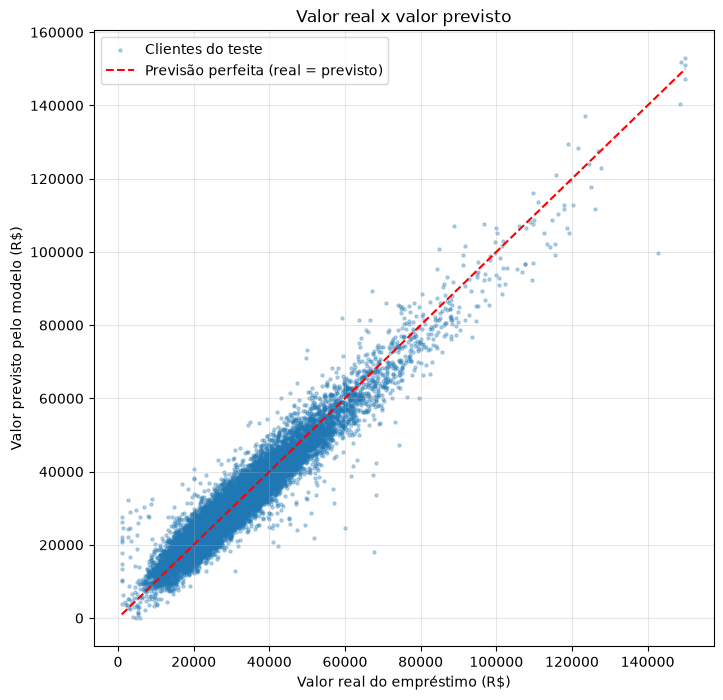

In [13]:
plt.figure(figsize=(8, 8))

plt.scatter(y_teste, previsoes, s=5, alpha=0.3, label="Clientes do teste")

extremos = [y_teste.min(), y_teste.max()]
plt.plot(extremos, extremos, color="red", linestyle="--", label="Previsão perfeita (real = previsto)")

plt.title("Valor real x valor previsto")
plt.xlabel("Valor real do empréstimo (R$)")
plt.ylabel("Valor previsto pelo modelo (R$)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [14]:
### As previsões estão próximas dos valores reais?

# Na maior parte dos casos, sim. Na tabela, quatro das dez previsões ficaram a menos de R$ 400 do valor real
# (linhas 2, 4, 5 e 7) e a maior diferença entre os dez exemplos foi de cerca de R$ 4,3 mil (linha 8).
# Considerando o teste inteiro, 82,6% das previsões erraram por até R$ 5.000.
# No gráfico, os pontos se concentram em volta da linha vermelha, que representa a previsão perfeita.
# Os maiores afastamentos aparecem nas pontas. Nos empréstimos mais baixos, os pontos ficam acima da linha,
# ou seja, o modelo costuma prever mais do que o valor real (e em 2 clientes chegou a prever valores negativos,
# o que não faz sentido). Nos empréstimos mais altos acontece o contrário: a maioria dos pontos fica abaixo
# da linha, e o modelo prevê menos do que o valor real.

In [15]:
## Etapa 8 – Fazer uma previsão

novo_cliente = pd.DataFrame({
    "idade": [29],
    "renda_mensal": [5500.00],
    "score_credito": [680],
    "historico_pagamentos": [88.0],
})

valor_previsto = modelo.predict(novo_cliente)[0]

print("Características do novo cliente:")
print(novo_cliente.to_string(index=False))
print(f"\nValor de empréstimo previsto: {reais(valor_previsto)}")

# Para conferir, calculei quanto receberam os clientes da base com perfil parecido
# (renda entre R$ 5.000 e R$ 6.000, score entre 650 e 710 e histórico entre 83 e 93)
parecidos = dados[
    dados["renda_mensal"].between(5000, 6000)
    & dados["score_credito"].between(650, 710)
    & dados["historico_pagamentos"].between(83, 93)
]
print(f"Média dos {len(parecidos)} clientes parecidos na base: {reais(parecidos['valor_emprestimo'].mean())}")

Características do novo cliente:
 idade  renda_mensal  score_credito  historico_pagamentos
    29        5500.0            680                  88.0

Valor de empréstimo previsto: R$ 27.771,85
Média dos 595 clientes parecidos na base: R$ 28.046,10


In [16]:
### Interpretação do resultado

# O cliente criado tem 29 anos, ganha R$ 5.500 por mês, tem score 680 (acima da média da base, que é 650)
# e histórico de pagamentos 88 (também acima da média, 82). Para esse perfil, o modelo sugere um empréstimo
# de R$ 27.771,85.
# O resultado é coerente: fica abaixo da média geral dos empréstimos (R$ 31.736) porque a renda dele é menor
# que a média da base (R$ 7.542), e fica bem próximo do que os clientes parecidos receberam (R$ 28.046,10).
# Mesmo assim, é uma estimativa: como o modelo erra em média uns R$ 3 mil, o valor ideal para esse cliente
# pode ficar um pouco acima ou abaixo do previsto.

In [17]:
## Etapa 9 – Conclusão

# Sim, o modelo de regressão apresentou resultados adequados para estimar o valor dos empréstimos.
# Usando idade, renda mensal, score de crédito e histórico de pagamentos, a regressão linear explicou cerca
# de 92% da variação dos valores (R² = 0,9216), errou em média R$ 3.039,13 (MAE) e ficou a até R$ 5.000 do
# valor real em 82,6% dos clientes do teste. A previsão para o novo cliente também foi coerente com o que
# clientes parecidos receberam na base.

# Principais limitações:
# 1. O resultado é uma estimativa, não um valor exato: o erro médio é de R$ 3 mil e alguns casos erram bem mais.
# 2. A regressão linear supõe que cada variável influencia o valor como uma reta. Nos extremos isso falha:
#    o modelo costuma prever acima do real nos empréstimos pequenos e abaixo do real nos mais altos, e em
#    2 casos chegou a prever valores negativos, que não existem na prática.
# 3. O modelo só conhece as quatro variáveis da base. Fatores importantes numa análise de crédito, como
#    dívidas atuais, profissão, tempo de emprego e garantias, ficaram de fora.
# 4. Ele aprende com as decisões tomadas no passado. Se a política de crédito da empresa mudar,
#    o modelo precisa ser treinado de novo.

# Por isso, o modelo pode ser usado como apoio para agilizar a análise de crédito, mas a decisão final
# sobre o empréstimo ainda deve passar por uma avaliação da empresa.